# Exploration du jeu NASA C-MAPSS FD001
**Partie 1 - Mouad AAMER**

Objectifs : comprendre les donnees, calculer le label RUL, reperer les capteurs inutiles (constants) avant l'ingestion.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

COLUMNS = ['engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3'] + [f's{i}' for i in range(1, 22)]

def load(path):
    df = pd.read_csv(path, sep=r'\s+', header=None)
    df = df.iloc[:, :len(COLUMNS)]
    df.columns = COLUMNS
    return df

train = load('../data/raw/train_FD001.txt')
test = load('../data/raw/test_FD001.txt')
rul_test = pd.read_csv('../data/raw/RUL_FD001.txt', header=None, names=['RUL'])
print('train :', train.shape, '| test :', test.shape, '| RUL test :', rul_test.shape)
train.head()

train : (20631, 26) | test : (13096, 26) | RUL test : (100, 1)


,engine_id,cycle,setting_1,setting_2,setting_3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 1. Duree de vie des moteurs (train)
Chaque moteur du jeu d'entrainement est suivi jusqu'a la panne : son dernier cycle = sa duree de vie.

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: cycle, dtype: float64


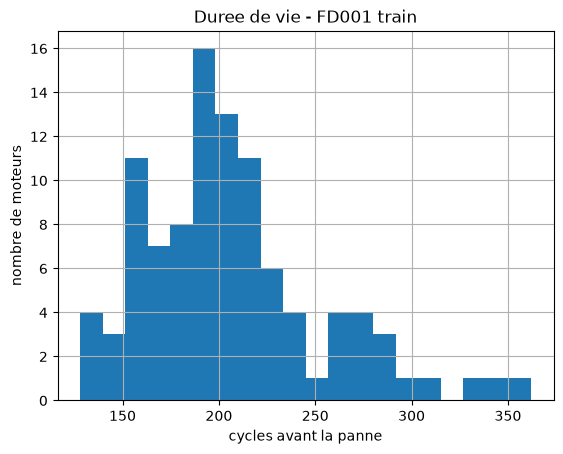

In [3]:
life = train.groupby('engine_id')['cycle'].max()
print(life.describe())
life.hist(bins=20)
plt.xlabel('cycles avant la panne'); plt.ylabel('nombre de moteurs'); plt.title('Duree de vie - FD001 train')
plt.show()

## 2. Capteurs constants
Un capteur dont l'ecart-type est quasi nul n'apporte aucune information -> a supprimer en zone Silver.

In [4]:
std = train[COLUMNS[2:]].std().sort_values()
print(std)
constant_cols = std[std < 1e-3].index.tolist()
print('\nColonnes quasi constantes :', constant_cols)

s1           0.000000e+00
setting_3    0.000000e+00
s10          0.000000e+00
s19          0.000000e+00
s18          0.000000e+00
s16          3.469531e-18
s5           5.329200e-15
setting_2    2.930621e-04
s6           1.388985e-03
setting_1    2.187313e-03
s15          3.750504e-02
s8           7.098548e-02
s13          7.191892e-02
s21          1.082509e-01
s20          1.807464e-01
s11          2.670874e-01
s2           5.000533e-01
s12          7.375534e-01
s7           8.850923e-01
s17          1.548763e+00
s3           6.131150e+00
s4           9.000605e+00
s14          1.907618e+01
s9           2.208288e+01
dtype: float64

Colonnes quasi constantes : ['s1', 'setting_3', 's10', 's19', 's18', 's16', 's5', 'setting_2']


## 3. Label RUL
RUL = cycle max du moteur - cycle courant. On la plafonne a 125 : au debut de vie le moteur est sain et sa degradation n'est pas encore visible.

In [5]:
train['RUL'] = train.groupby('engine_id')['cycle'].transform('max') - train['cycle']
train['RUL_cap'] = train['RUL'].clip(upper=125)

def etat(rul):
    if rul <= 15: return 'Critique'
    if rul <= 50: return 'A surveiller'
    return 'Sain'

train['etat'] = train['RUL'].apply(etat)
print(train['etat'].value_counts())

etat
Sain            15531
A surveiller     3500
Critique         1600
Name: count, dtype: int64


## 4. Capteurs les plus lies a la RUL

s11   -0.775230
s4    -0.757157
s15   -0.720858
s17   -0.680829
s2    -0.678458
s3    -0.655030
s8    -0.624568
s13   -0.624034
s9    -0.462151
s14   -0.369753
s6    -0.108289
s20    0.704626
s21    0.707334
s7     0.733021
s12    0.748870
Name: RUL_cap, dtype: float64


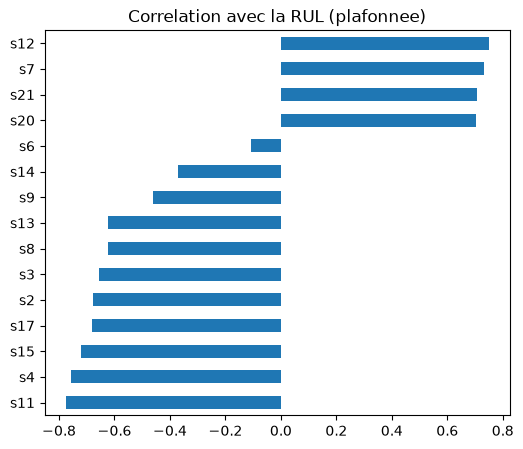

In [6]:
useful = [c for c in COLUMNS[5:] if c not in constant_cols]
corr = train[useful + ['RUL_cap']].corr()['RUL_cap'].drop('RUL_cap').sort_values()
print(corr)
corr.plot.barh(figsize=(6, 5), title='Correlation avec la RUL (plafonnee)')
plt.show()

## 5. Evolution des capteurs pour quelques moteurs

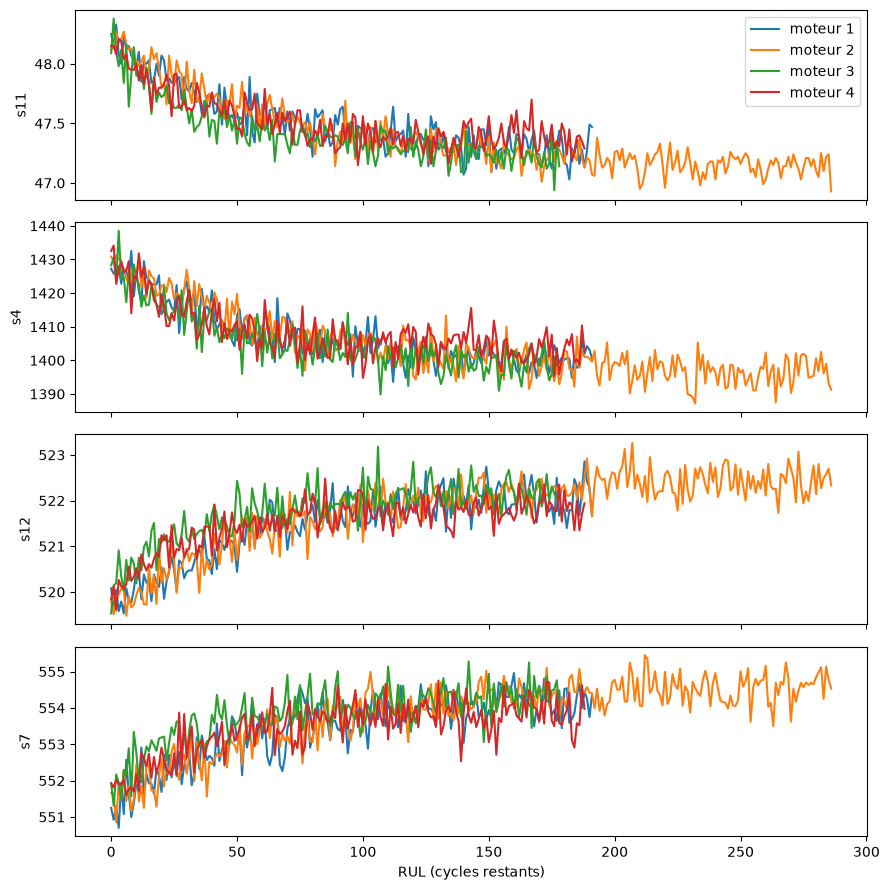

In [7]:
top = corr.abs().sort_values(ascending=False).index[:4]
fig, axes = plt.subplots(len(top), 1, figsize=(9, 9), sharex=True)
for ax, s in zip(axes, top):
    for e in [1, 2, 3, 4]:
        d = train[train.engine_id == e]
        ax.plot(d['RUL'], d[s], label=f'moteur {e}')
    ax.set_ylabel(s); ax.invert_xaxis()
axes[0].legend(); axes[-1].set_xlabel('RUL (cycles restants)')
plt.tight_layout(); plt.show()

## Conclusions

- **Données** : 100 moteurs suivis jusqu'à la panne. Durée de vie entre 128 et 362 cycles (moyenne 206).
- **Capteurs inutiles** : s1, s5, s10, s16, s18, s19 et setting_3 ne varient pas. On les supprime en zone Silver.
- **Capteurs utiles** : s11, s4, s12 et s7 sont les plus liés à la RUL. Ils changent nettement quand le moteur approche de la panne.
- **RUL plafonnée à 125** : les capteurs restent stables au début de vie, la dégradation n'est visible que dans les ~125 derniers cycles.
- **Classes déséquilibrées** : 75 % Sain, 17 % À surveiller, 8 % Critique. Il faudra évaluer le classifieur avec le F1-score, pas seulement la  précision.
- **Bruit** : les signaux sont bruités, d'où l'utilisation de moyennes glissantes (5, 10, 20 cycles).